##Classical B

In [1]:

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor, Compose, Normalize

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

In [2]:
import os
# --- Dataset Path (supports running from notebooks/ or root) ---
# Original: root="./data"
data_dir = "./data" if os.path.exists("./data") else "notebooks/data"

# Load MNIST dataset
train_dataset = MNIST(
  root=data_dir,
  train=True,
  transform=ToTensor(),
  download=False
)


In [3]:
# Take a subset for faster visualization (5000 samples)
N_SAMPLES = 5000
indices = np.random.choice(len(train_dataset), N_SAMPLES, replace=False)

# Extract images and labels
images = []
labels = []

for idx in indices:
  img, label = train_dataset[idx]
  img = img.numpy().flatten() # Flatten makes each 28x28 image into 784D
  images.append(img)
  labels.append(label)

X = np.array(images)  # Shape: (5000, 784)
y = np.array(labels)  # Ground truth labels (for visualization)

print(f"Data shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Unique labels: {np.unique(y)}")

Data shape: (5000, 784)
Labels shape: (5000,)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


##Part 1 : Dimensional Reduction


In [4]:
# We use n_components = total features (784) to analyze the importance of every component.
# In reality, if we wanted to actually compress the data to a smaller size, we would pick a smaller number (e.g., 50).
pca_full = PCA(n_components=28*28)
pca_full.fit(X)

# Calculate cumulative variance
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

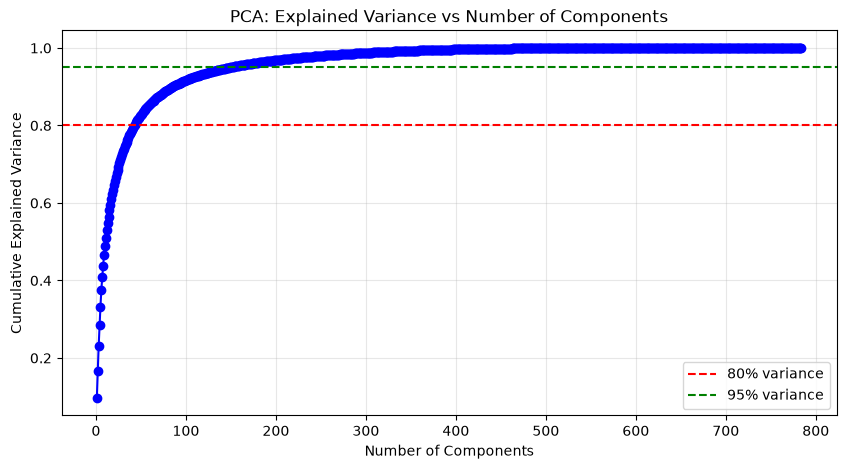

In [5]:
# Plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, 785), cumulative_variance, 'bo-')
plt.axhline(y=0.80, color='r', linestyle='--', label='80% variance')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA: Explained Variance vs Number of Components')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# Create 5 targets from 0.80 (80%) to 0.95 (95%)
targets = np.linspace(0.80, 0.95, 5)

for target in targets:
  # Find the first index where variance is >= target
  # np.argmax returns the index of the first True value
  n_components = np.argmax(cumulative_variance >= target) + 1

  print(f"To keep {target:.2%} variance, you need {n_components} components.")

To keep 80.00% variance, you need 43 components.
To keep 83.75% variance, you need 54 components.
To keep 87.50% variance, you need 70 components.
To keep 91.25% variance, you need 96 components.
To keep 95.00% variance, you need 150 components.


In [7]:
# Apply PCA to reduce to 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print(f"Original shape: {X.shape}")
print(f"After PCA: {X_pca.shape}")
print(f"Variance explained by 2 components: {pca.explained_variance_ratio_.sum():.2%}")

Original shape: (5000, 784)
After PCA: (5000, 2)
Variance explained by 2 components: 16.67%


##t-SNE


In [8]:
# Apply t-SNE
print("Running t-SNE... (this may take a minute)")

tsne = TSNE(
  n_components=2,
  random_state=42,
)
X_tsne = tsne.fit_transform(X)

print(f"After t-SNE: {X_tsne.shape}")

Running t-SNE... (this may take a minute)
After t-SNE: (5000, 2)


PCA vs t-SNE Comparison

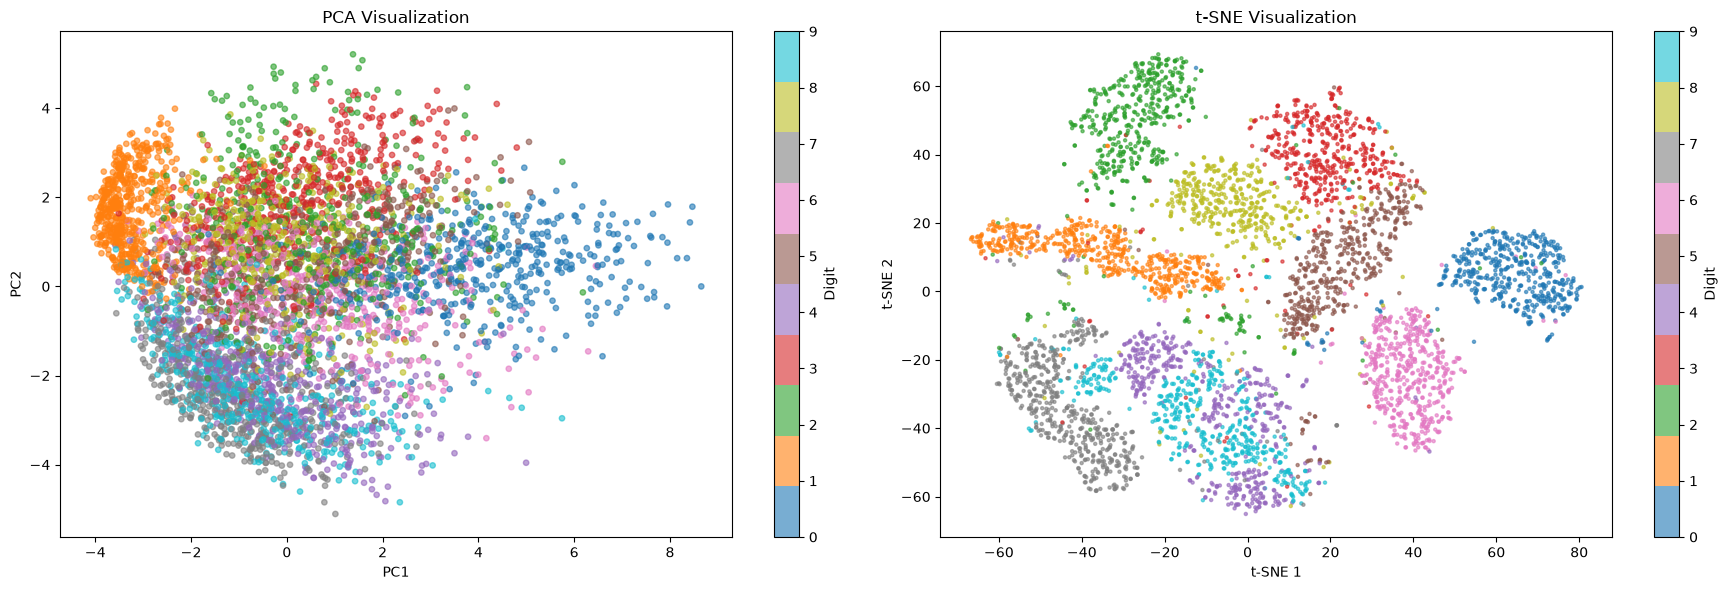

In [9]:
# Side by side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# PCA
scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.6, s=15)
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_title('PCA Visualization')
plt.colorbar(scatter1, ax=ax1, label='Digit')

# t-SNE
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', alpha=0.6, s=5)
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
ax2.set_title('t-SNE Visualization')
plt.colorbar(scatter2, ax=ax2, label='Digit')

plt.tight_layout()
plt.show()



##K means clustering

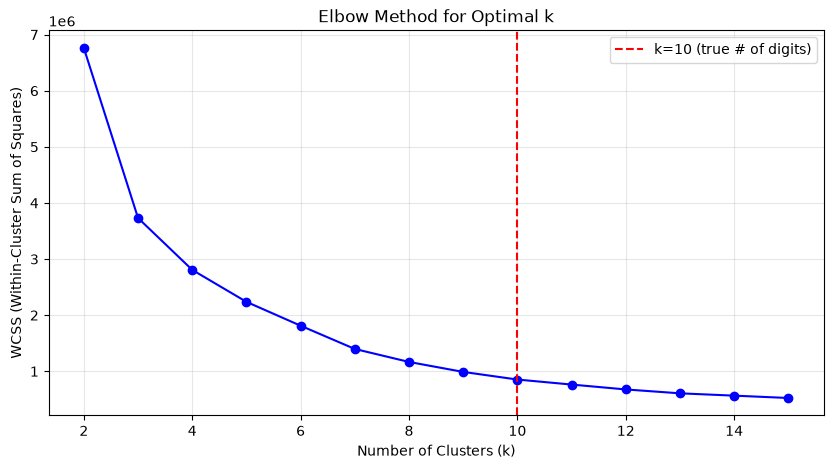

In [10]:
# Let's first demonstrate the Elbow Method
wcss = []  # Within-Cluster Sum of Squares
k_range = range(2, 16)

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_tsne)  # Using t-SNE reduced data
  wcss.append(kmeans.inertia_)

# Plot the Elbow
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, 'bo-')
plt.axvline(x=10, color='r', linestyle='--', label='k=10 (true # of digits)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.title('Elbow Method for Optimal k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
K = 10  # Apply K-Means with k=10
n_init = 10 # Repeat the clustering process 10 times

kmeans = KMeans(n_clusters=K, random_state=42, n_init=n_init)

pca_clusters = kmeans.fit_predict(X_pca)  # Using PCA reduced data
tsne_clusters = kmeans.fit_predict(X_tsne)  # Using t-SNE reduced data

print(f"clusters: {np.unique(pca_clusters)}")

clusters: [0 1 2 3 4 5 6 7 8 9]


Visualizing Cluster Assignments vs Ground Truth

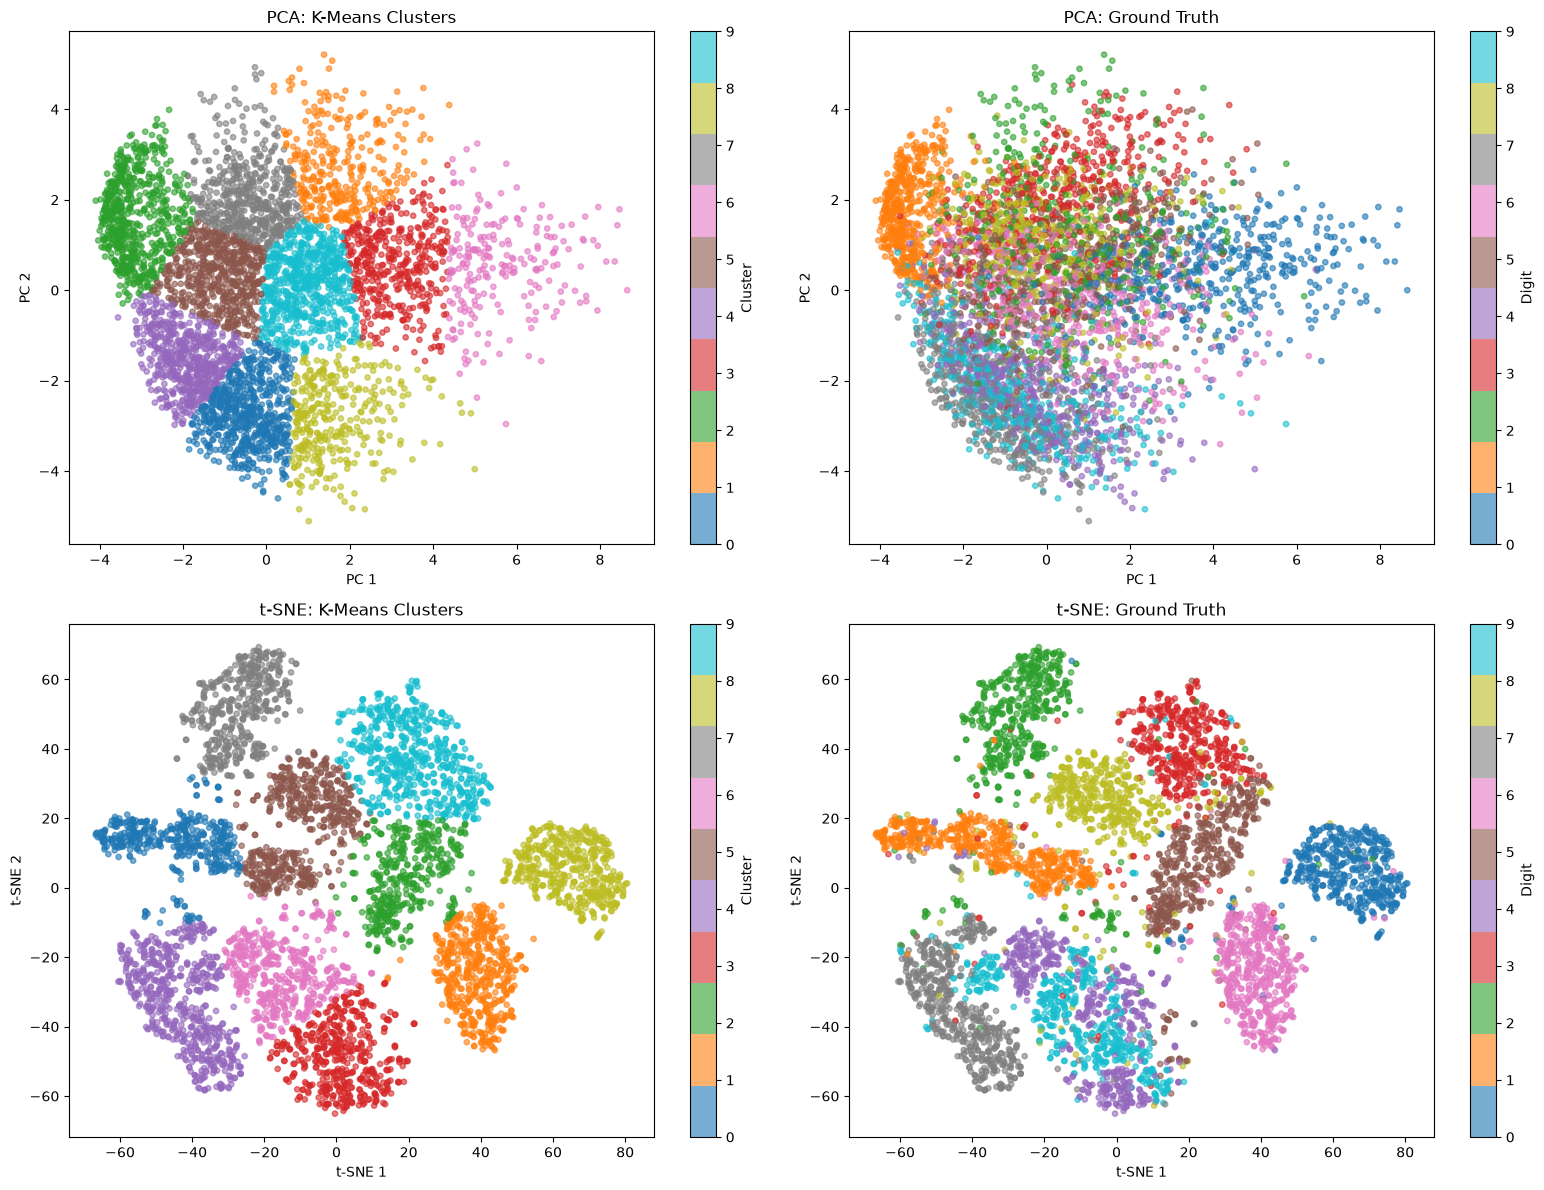

In [12]:
import matplotlib.pyplot as plt

# Create 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Row 1: PCA ---

# Plot 1: PCA - K-Means Clusters
scatter1 = axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=pca_clusters, cmap='tab10', alpha=0.6, s=15)
axes[0, 0].set_title('PCA: K-Means Clusters')
axes[0, 0].set_xlabel('PC 1')
axes[0, 0].set_ylabel('PC 2')
plt.colorbar(scatter1, ax=axes[0, 0], label='Cluster')

# Plot 2: PCA - Ground Truth
scatter2 = axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.6, s=15)
axes[0, 1].set_title('PCA: Ground Truth')
axes[0, 1].set_xlabel('PC 1')
axes[0, 1].set_ylabel('PC 2')
plt.colorbar(scatter2, ax=axes[0, 1], label='Digit')

# --- Row 2: t-SNE ---

# Plot 3: t-SNE - K-Means Clusters
scatter3 = axes[1, 0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=tsne_clusters, cmap='tab10', alpha=0.6, s=15)
axes[1, 0].set_title('t-SNE: K-Means Clusters')
axes[1, 0].set_xlabel('t-SNE 1')
axes[1, 0].set_ylabel('t-SNE 2')
plt.colorbar(scatter3, ax=axes[1, 0], label='Cluster')

# Plot 4: t-SNE - Ground Truth
scatter4 = axes[1, 1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', alpha=0.6, s=15)
axes[1, 1].set_title('t-SNE: Ground Truth')
axes[1, 1].set_xlabel('t-SNE 1')
axes[1, 1].set_ylabel('t-SNE 2')
plt.colorbar(scatter4, ax=axes[1, 1], label='Digit')


plt.tight_layout()
plt.show()